# Домашнее задание: дизайн эксперимента

Выполнил: Тюрин Данил

In [27]:
import pandas as pd
from typing import Iterable, Optional
import numpy as np
from scipy.stats import ttest_ind, chisquare

## Проверяю качество данных

#### Функции для дальнейшей проверки качества данных

In [28]:
user_week_metrics = pd.read_csv("user_week_metrics.csv")
users = pd.read_csv("users.csv")


# Взял готовые функции из лекции по ad-hoc
def summarize_dq(df: pd.DataFrame, key_cols: Optional[Iterable[str]] = None) -> pd.DataFrame:
    rows = []
    rows.append({"проверка": "строк всего", "значение": len(df)})
    rows.append({"проверка": "полных дублей строк", "значение": int(df.duplicated().sum())})
    for c in df.columns:
        rows.append({"проверка": f"пропуски: {c}", "значение": int(df[c].isna().sum())})
    if key_cols:
        key_cols = list(key_cols)
        rows.append({
            "проверка": f"дубли по ключу: {'+'.join(key_cols)}",
            "значение": int(df.duplicated(key_cols).sum()),
        })
    return pd.DataFrame(rows)

def one_pager(
    decision: str,
    context: str,
    what_done: str,
    result: str,
    limits: str,
    action: str,
) -> str:
    # Собирает итоговую справку с выводом наверху.
    parts = [
        "=" * 60,
        "ИТОГОВАЯ СПРАВКА",
        "=" * 60,
        "",
        "Решение:",
        decision,
        "",
        "Контекст:",
        context,
        "",
        "Что сделали:",
        what_done,
        "",
        "Результат:",
        result,
        "",
        "Ограничения:",
        limits,
        "",
        "Рекомендованное действие:",
        action,
        "=" * 60,
    ]
    return "\n".join(parts)


#### Проверяю дубли и пропуски

In [29]:
display(summarize_dq(users, key_cols=["user_id"]))

,проверка,значение
0,строк всего,388000
1,полных дублей строк,0
2,пропуски: user_id,0
3,пропуски: user_type,0
4,пропуски: reg_date,0
5,пропуски: region_group,8000
6,пропуски: platform,8000
7,пропуски: company_size,380000
8,дубли по ключу: user_id,0


In [30]:
display(summarize_dq(user_week_metrics, key_cols=["user_id", "week_start"]))

,проверка,значение
0,строк всего,870685
1,полных дублей строк,0
2,пропуски: week_start,0
3,пропуски: user_id,0
4,пропуски: user_type,0
5,пропуски: vacancy_views_app,47147
6,пропуски: responses_app,47147
7,пропуски: relevant_responses_app,47147
8,пропуски: invitations_app,47147
9,пропуски: responses_emp,823538


#### Метрики соответствуют типу пользователя

In [31]:
applicants = user_week_metrics[user_week_metrics["user_type"] == "APPLICANT"]
employers = user_week_metrics[user_week_metrics["user_type"] == "EMPLOYER"]

display(summarize_dq(applicants))
display(summarize_dq(employers))

,проверка,значение
0,строк всего,823538
1,полных дублей строк,0
2,пропуски: week_start,0
3,пропуски: user_id,0
4,пропуски: user_type,0
5,пропуски: vacancy_views_app,0
6,пропуски: responses_app,0
7,пропуски: relevant_responses_app,0
8,пропуски: invitations_app,0
9,пропуски: responses_emp,823538


,проверка,значение
0,строк всего,47147
1,полных дублей строк,0
2,пропуски: week_start,0
3,пропуски: user_id,0
4,пропуски: user_type,0
5,пропуски: vacancy_views_app,47147
6,пропуски: responses_app,47147
7,пропуски: relevant_responses_app,47147
8,пропуски: invitations_app,47147
9,пропуски: responses_emp,0


#### Метрики правильно рассчитаны

In [32]:
cols = ["vacancy_views_app", "responses_app",
        "relevant_responses_app", "invitations_app"]

print("Отрицательные значения:", (applicants[cols] < 0).sum().sum())
print("Дробные значения:", (applicants[cols] % 1 != 0).sum().sum())

print("Приглашений больше, чем релевантных откликов:",
      (applicants["invitations_app"] > applicants["relevant_responses_app"]).sum())

print("Релевантных откликов больше, чем всех откликов:",
      (applicants["relevant_responses_app"] > applicants["responses_app"]).sum())

Отрицательные значения: 0
Дробные значения: 0
Приглашений больше, чем релевантных откликов: 0
Релевантных откликов больше, чем всех откликов: 0


#### Период истории, который подходит под прогноз

In [33]:
# Сколько соискателей заходили на сайт каждую неделю
active = applicants.groupby("week_start")["user_id"].nunique()

# Сколько из них отправили хотя бы один отклик
with_response = applicants[applicants["responses_app"] > 0]
responded = with_response.groupby("week_start")["user_id"].nunique()

weekly = pd.DataFrame({
    "Заходили на сайт": active,
    "Отправили хотя бы один отклик": responded
})

display(weekly)

,Заходили на сайт,Отправили хотя бы один отклик
week_start,,
2026-03-09,102701,94675
2026-03-16,103872,95857
2026-03-23,103090,95082
2026-03-30,101859,93844
2026-04-06,102791,94868
2026-04-13,103926,95994
2026-04-20,102599,94635
2026-04-27,53178,34259
2026-05-04,49522,31660


#### Считаю MDE целевой метрики и guardrail по формуле из лекции + строю график

In [34]:
start = pd.Timestamp("2026-04-06")
dates = pd.to_datetime(applicants["week_start"])
rows = []

for weeks in range(1, 6):
    end = start + pd.Timedelta(weeks=weeks)
    period = applicants[(dates >= start) & (dates < end)]

    cols = ["responses_app", "relevant_responses_app", "invitations_app"]
    people = period.groupby("user_id")[cols].sum()
    people = people[people["responses_app"] > 0]

    n = len(people) // 2
    relevant = people["relevant_responses_app"]
    invites = people["invitations_app"]


    mde_relevant = (1.96 + 0.842) * relevant.std() * (2 / n)**0.5 / relevant.mean() * 100
    mde_invites = (1.645 + 0.842) * invites.std() * (2 / n)**0.5 / invites.mean() * 100

    rows.append([weeks, len(people), mde_relevant, mde_invites])

result = pd.DataFrame(rows, columns=[
    "Недель", "Соискателей", "MDE откликов, %", "MDE приглашений, %"
])
display(result.round(2))

,Недель,Соискателей,"MDE откликов, %","MDE приглашений, %"
0,1,94868,1.95,3.85
1,2,156331,1.71,3.08
2,3,197889,1.62,2.81
3,4,208531,1.79,2.91
4,5,216512,1.97,3.04


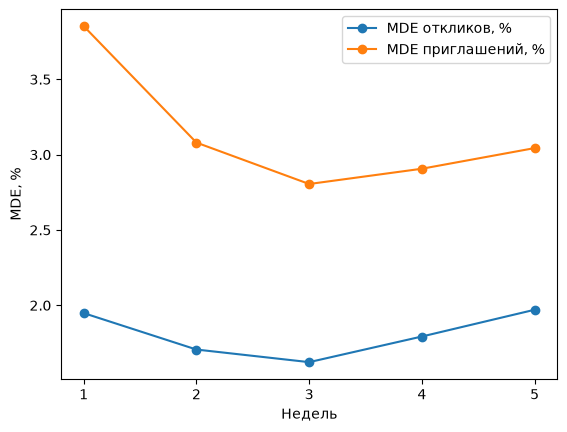

In [35]:
import matplotlib.pyplot as plt

result.plot(
    x="Недель",
    y=["MDE откликов, %", "MDE приглашений, %"],
    marker="o"
)

plt.xticks([1, 2, 3, 4, 5])
plt.ylabel("MDE, %")
plt.show()

### A/A на истории

In [36]:
dates = pd.to_datetime(applicants["week_start"])
period = applicants[(dates >= "2026-04-06") & (dates < "2026-04-27")]

people = period.groupby("user_id")[["responses_app", "relevant_responses_app"]].sum()
people = people[people["responses_app"] > 0]

# Одно число на человека — сколько у него было релевантных откликов
relevant = people["relevant_responses_app"].to_numpy()
print(len(relevant))

197889


In [37]:
rng = np.random.default_rng(42)
runs = 1000
significant = 0

for i in range(runs):
    in_a = rng.random(len(relevant)) < 0.5
    group_a = relevant[in_a]
    group_b = relevant[~in_a]

    p = ttest_ind(group_a, group_b, equal_var=False).pvalue
    if p < 0.05:
        significant += 1

    if i == 0:
        sizes = [len(group_a), len(group_b)]
        print("Размеры групп:", sizes)
        print("p-value для SRM:", round(chisquare(sizes).pvalue, 3))

print("Запусков с p < 0.05:", significant)
print("Доля таких запусков:", f"{significant / runs:.1%}")

Размеры групп: [98902, 98987]
p-value для SRM: 0.848
Запусков с p < 0.05: 43
Доля таких запусков: 4.3%
